# Customer behavior: missing labels and unbalanced classes

MohammadMahdi Faraji. Homework 1 of the Machine Learning course (Prof. Hamed Baghban), rebuilt after the course as a worked example for people who are just starting with machine learning.

An online shop gave us a table of 1000 customers: age, gender, region, how much they spent, how long they stayed on the website, how many products they looked at, five unnamed number columns, and what kind of product they bought (`Purchase_Category`). For 700 of the 1000 customers, that last column is empty.

The homework had six tasks ([`docs/assignment.md`](../docs/assignment.md)). This notebook answers them in order:

1. correlation between the features, and removing features that are not needed
2. filling in the missing categories
3. a bar chart of the categories, a discussion of balance, and a way to make it more balanced
4. confusion matrix and F1 score
5. how the customers behave, and which customers are valuable
6. how an unbalanced distribution affects accuracy

**The short version.** The empty cells are spread at random, and none of the columns tells us which category a customer bought. Every model I tried is exactly as good as always answering "Electronics", the most common category: about 65 % accuracy, which sounds fine until you notice that it never finds a single book buyer. My first version of this homework fell into exactly that trap. So most of this notebook is about measuring honestly: with the right baseline, with metrics that are not fooled by a big class, and without testing a model on data it filled in itself.

**How to run it**
- **Colab:** *Runtime → Run all*. It asks you to upload `synthetic_customer_behavior.csv` (from the `data/` folder of the repository). Takes about 2 minutes.
- **Locally:** `pip install -r requirements.txt`, then open this notebook in Jupyter from the `notebooks/` folder and run all cells. The plots and tables are saved in `results/`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             recall_score, silhouette_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, permutation_test_score,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
try:
    import imblearn
except ImportError:   # imbalanced-learn is not installed (for example in an older Colab)
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'], check=True)
    import imblearn
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import make_pipeline as make_imb_pipeline

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 3)
print('python', sys.version.split()[0], '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| imbalanced-learn', imblearn.__version__)

python 3.14.3 | pandas 3.1.0 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2


In [2]:
DATA_NAME = 'synthetic_customer_behavior.csv'
IN_COLAB = 'google.colab' in sys.modules

# the data is in data/ of the repository; in Colab without the repository, upload the file
candidates = [Path('..') / 'data' / DATA_NAME, Path('data') / DATA_NAME, Path(DATA_NAME)]
if IN_COLAB:
    candidates += list(Path('/content').glob(f'*/data/{DATA_NAME}'))
data_file = next((p for p in candidates if p.exists()), None)
if data_file is None and IN_COLAB:
    from google.colab import files
    print('please upload', DATA_NAME)
    data_file = Path(list(files.upload().keys())[0])
if data_file is None:
    raise FileNotFoundError(f'{DATA_NAME} not found; run the notebook from the notebooks/ folder of the repository')

# plots and tables go to results/ of the repository (or to a new results/ folder in Colab)
RESULTS = Path('..') / 'results' if (Path('..') / 'results').is_dir() else Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches='tight')


df = pd.read_csv(data_file)
print(data_file, df.shape)

..\data\synthetic_customer_behavior.csv (1000, 12)


## 0. A first look at the data

In [3]:
df.head()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Age,Gender,Region,Purchase_Category,Purchase_Amount,Time_Spent_on_Website,Number_of_Items_Viewed
0,-6.470,-2.850,-1.296,-0.554,-6.158,22,Female,South,NaN,41.880,10.771,3
1,-9.419,9.645,7.583,-4.910,-5.103,43,Male,North,Electronics,117.430,24.053,9
2,-8.743,9.334,5.967,-4.353,-7.731,58,Male,West,Clothing,216.717,5.747,13
3,-3.468,4.095,3.597,0.534,-8.134,68,Male,East,NaN,62.612,16.646,1
4,-0.971,10.432,5.366,0.644,-6.133,64,Male,West,NaN,36.512,15.734,15


In [4]:
NUM = ['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Age',
       'Purchase_Amount', 'Time_Spent_on_Website', 'Number_of_Items_Viewed']
CAT = ['Gender', 'Region']
TARGET = 'Purchase_Category'

df[NUM].describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
Feature_1,-6.335,2.983,-13.471,2.488
Feature_2,1.414,8.096,-12.538,13.846
Feature_3,4.776,3.114,-3.758,11.062
Feature_4,-0.739,3.574,-10.231,7.062
Feature_5,-3.314,4.774,-10.765,9.839
Age,43.807,14.968,18.000,69.000
Purchase_Amount,100.191,69.223,0.438,427.895
Time_Spent_on_Website,15.604,8.431,1.000,29.981
Number_of_Items_Viewed,9.937,5.511,1.000,19.000


In [5]:
for col in CAT + [TARGET]:
    print(df[col].value_counts(dropna=False).to_dict())
print('\nempty cells per column:', df.isna().sum()[df.isna().sum() > 0].to_dict())

{'Male': 516, 'Female': 484}
{'West': 275, 'North': 252, 'South': 244, 'East': 229}
{nan: 700, 'Electronics': 194, 'Clothing': 50, 'Groceries': 36, 'Books': 20}

empty cells per column: {'Purchase_Category': 700}


What the columns are:
- `Feature_1` … `Feature_5`: numbers without a name or a description. As we will see, they look like they were made by a random data generator.
- `Age` (18 to 69), `Gender` (516 men, 484 women), `Region` (East, North, South, West, between 229 and 275 customers each).
- `Purchase_Amount`: how much the customer spent (from 0.4 to 428; the sheet gives no currency).
- `Time_Spent_on_Website` (1 to 30, probably minutes) and `Number_of_Items_Viewed` (1 to 19).
- `Purchase_Category`: Electronics, Clothing, Groceries or Books. This is the column with **700 empty cells**. Only 300 customers have a known category.

The file is called *synthetic* customer behavior, so this is generated data, not a real shop. That's fine for practicing, but it is good to keep in mind when we interpret the results.

### Are the categories missing at random?

Before filling anything in, it's worth asking *why* a value is missing. There are three typical cases:
- **completely at random:** a coin decided which cells are empty. The customers with and without a category are the same kind of people.
- **depending on other columns:** for example, the category is missing more often for older customers.
- **depending on the missing value itself:** for example, book buyers never fill in the form. This case is the hardest, because the data can't show it.

We can check the first two. If the categories are missing at random, the 300 customers with a category and the 700 without one should look the same in every column.

In [6]:
known = df[TARGET].notna()
rows = []
for col in NUM:
    p = stats.ttest_ind(df.loc[known, col], df.loc[~known, col], equal_var=False).pvalue
    rows.append([col, df.loc[known, col].mean(), df.loc[~known, col].mean(), p])
for col in CAT:
    p = stats.chi2_contingency(pd.crosstab(df[col], known))[1]
    rows.append([col, '', '', p])
pd.DataFrame(rows, columns=['column', 'mean (category known)', 'mean (category missing)', 'p-value']).set_index('column')

,mean (category known),mean (category missing),p-value
column,,,
Feature_1,-6.236,-6.377,0.511
Feature_2,1.916,1.2,0.199
Feature_3,4.954,4.7,0.234
Feature_4,-0.755,-0.733,0.929
Feature_5,-3.672,-3.161,0.111
Age,44.287,43.601,0.498
Purchase_Amount,101.504,99.628,0.696
Time_Spent_on_Website,15.704,15.562,0.809
Number_of_Items_Viewed,10.293,9.784,0.181


In [7]:
# a second test: can a model tell which rows are missing their category?
prep = ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(drop='if_binary'), CAT)])
auc = cross_val_score(make_pipeline(prep, LogisticRegression(max_iter=1000)), df[NUM + CAT], ~known,
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc')
print(f'ROC AUC for "is the category missing?": {auc.mean():.3f} (0.5 = no better than a coin)')

ROC AUC for "is the category missing?": 0.497 (0.5 = no better than a coin)


All p-values are large (the smallest is 0.11), and a model can't tell the two groups apart (AUC 0.50, the same as flipping a coin). So the categories look **missing completely at random**. This is good news: the 300 known rows are a fair sample of all 1000 customers, and we can learn from them without a bias.

## 1. Correlation between the features (task 1)

The **correlation coefficient** *r* says how strongly two number columns move together on a straight line: +1 means "when one goes up, the other goes up exactly in step", −1 means the opposite, and 0 means no straight-line connection. I use all 1000 rows here, because the category is not needed for this.

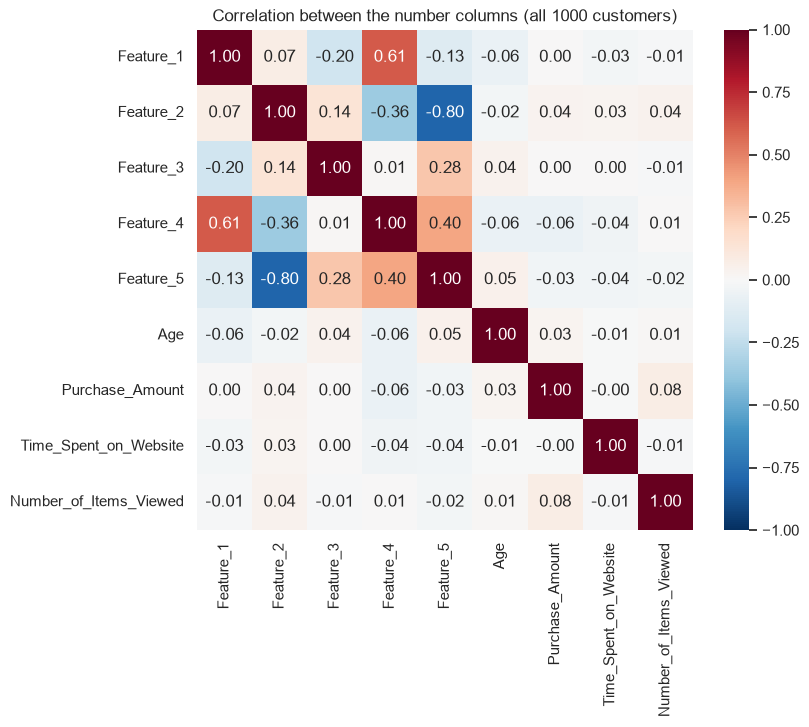

In [8]:
corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation between the number columns (all 1000 customers)')
save(fig, 'correlation_heatmap.png')
plt.show()

Only the five unnamed features are connected to each other: `Feature_2` and `Feature_5` have *r* = −0.80, and `Feature_1` and `Feature_4` have *r* = 0.61. Everything else is close to 0: age, spending, time on the website and the number of viewed products have nothing to do with each other or with the five features.

Where do the strong pairs come from? A scatter plot of the five features shows it right away:

2 groups: silhouette 0.395
3 groups: silhouette 0.495
4 groups: silhouette 0.593
5 groups: silhouette 0.491
6 groups: silhouette 0.388


7 groups: silhouette 0.301
customers per group: [250 250 250 250]


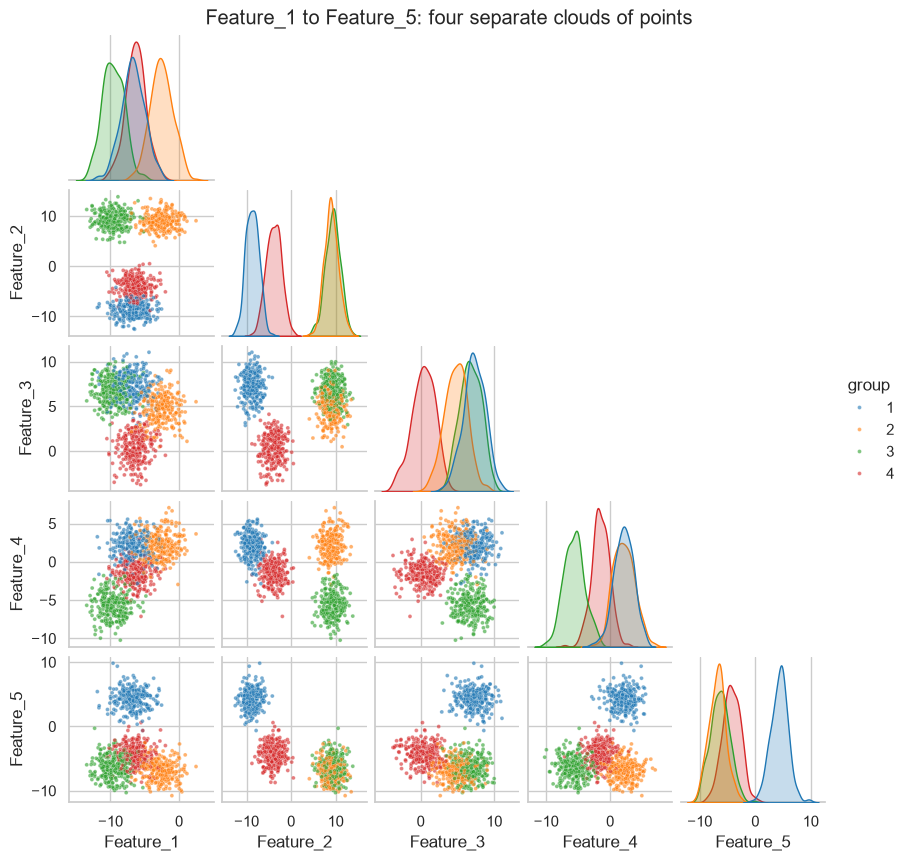

In [9]:
Z = StandardScaler().fit_transform(df[NUM[:5]])
for k in range(2, 8):
    labels = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
    print(f'{k} groups: silhouette {silhouette_score(Z, labels):.3f}')

group = KMeans(4, n_init=10, random_state=SEED).fit_predict(Z) + 1
print('customers per group:', np.bincount(group)[1:])
grid = sns.pairplot(df[NUM[:5]].assign(group=group), hue='group', corner=True, palette='tab10',
                    plot_kws={'s': 8, 'alpha': 0.6}, height=1.7)
grid.figure.suptitle('Feature_1 to Feature_5: four separate clouds of points', y=1.01)
save(grid.figure, 'feature_groups.png')
plt.show()

The five features form **four separate clouds with exactly 250 customers each**. The *silhouette* score measures how cleanly points fall into groups (1 = perfectly separated, 0 = no groups at all), and it is clearly highest for 4 groups (0.59). Real customer data almost never splits into four groups of exactly the same size; this is what a random data generator (like scikit-learn's `make_blobs`) produces. The strong correlations come from where the four cloud centers happen to lie, not from any real connection.

**Which columns are related to the category?** For number columns I use an **ANOVA F-test** (do the four categories have different averages?). For gender and region I use a **chi-square test** and **Cramér's V** (0 = no connection, 1 = the column decides the category completely). Only the 300 customers with a known category can be used here.

In [10]:
d = df[known]
F, p_num = f_classif(d[NUM], d[TARGET])
rows = [[col, 'ANOVA F', f, p] for col, f, p in zip(NUM, F, p_num)]
for col in CAT:
    table = pd.crosstab(d[col], d[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append([col, "Cramér's V", np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p])
table = pd.crosstab(group[known], d[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(table)
rows.append(['group of Feature_1..5', "Cramér's V", np.sqrt(chi2 / (table.values.sum() * 3)), p])
relation = pd.DataFrame(rows, columns=['column', 'test', 'value', 'p-value']).set_index('column').sort_values('p-value')
relation

,test,value,p-value
column,,,
Feature_3,ANOVA F,4.266,0.006
Gender,Cramér's V,0.187,0.015
Age,ANOVA F,1.712,0.165
group of Feature_1..5,Cramér's V,0.118,0.184
Number_of_Items_Viewed,ANOVA F,0.694,0.556
Feature_4,ANOVA F,0.454,0.714
Feature_2,ANOVA F,0.379,0.768
Purchase_Amount,ANOVA F,0.373,0.773
Region,Cramér's V,0.078,0.787


In [11]:
print('average Feature_3 per category:', d.groupby(TARGET)['Feature_3'].mean().round(2).to_dict())
print(pd.crosstab(d['Gender'], d[TARGET]))

average Feature_3 per category: {'Books': 6.45, 'Clothing': 5.63, 'Electronics': 4.83, 'Groceries': 3.84}
Purchase_Category  Books  Clothing  Electronics  Groceries
Gender                                                    
Female                15        29           83         15
Male                   5        21          111         21


Almost nothing is related to the category. Two columns have a p-value under 0.05:
- `Feature_3` (p = 0.006): book buyers have a slightly higher `Feature_3` on average.
- `Gender` (p = 0.015, Cramér's V = 0.19): 15 of the 20 book buyers are women.

Both are weak, and we tested 12 columns. With 12 tests, the chance that at least one gives p < 0.05 *by pure luck* is about 46 %. A common correction (Bonferroni) divides 0.05 by the number of tests, 0.05 / 12 ≈ 0.004, and neither column passes it. So these two hints may be real, but they may also be chance. Section 4 checks whether they help a model.

**Should any column be removed?** I keep all of them, for three reasons:
- **No column is a copy of another.** The strongest pair, `Feature_2` and `Feature_5`, has *r* = −0.80. A common rule of thumb is to drop one of two columns only above about 0.9, when they really carry the same information. Tree models are not bothered by correlated columns anyway.
- **Picking columns by their connection to the category doesn't pay off here.** One could keep only `Feature_3` and `Gender`, but that choice would be made by looking at the same 300 rows that are later used to test the model, which makes the test too optimistic. Section 4 shows that the models are no better with fewer columns.
- **Task 5 needs the spending columns.** `Purchase_Amount`, `Time_Spent_on_Website` and `Number_of_Items_Viewed` describe how valuable a customer is. My first version removed `Purchase_Amount`, which is exactly the column task 5 is about.

## 2. Filling in the missing categories (task 2)

There are three common ways to fill in a missing category:
- **the most common value (mode):** every empty cell becomes "Electronics".
- **a model:** train a classifier on the 300 known rows and let it predict the other 700. This is what my first version did.
- **random draws with the known shares:** each empty cell gets a category drawn at random, with the same probabilities as in the 300 known rows (65 % Electronics, 17 % Clothing, 12 % Groceries, 7 % Books).

A model is only better than the mode if it can actually predict the category. Section 4 measures this carefully; the short answer is that it can't: every model ends up answering "Electronics" almost every time. Let's see what each method does to the counts:

In [12]:
prep = ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(drop='if_binary'), CAT)])
X_known, y_known = df.loc[known, NUM + CAT], df.loc[known, TARGET]
X_missing = df.loc[~known, NUM + CAT]
CLASSES = sorted(y_known.unique())

forest = make_pipeline(prep, RandomForestClassifier(100, random_state=SEED)).fit(X_known, y_known)
by_model = forest.predict(X_missing)

shares = y_known.value_counts(normalize=True)
rng = np.random.default_rng(SEED)
by_draw = rng.choice(shares.index, size=(~known).sum(), p=shares.values)

fill = pd.DataFrame({
    'known (300)': y_known.value_counts(),
    'filled by the mode (700)': pd.Series(['Electronics'] * (~known).sum()).value_counts(),
    'filled by a model (700)': pd.Series(by_model).value_counts(),
    'filled by random draws (700)': pd.Series(by_draw).value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
fill

,known (300),filled by the mode (700),filled by a model (700),filled by random draws (700)
Books,20,0,0,42
Clothing,50,0,10,129
Electronics,194,700,687,445
Groceries,36,0,3,84


The model behaves almost exactly like the mode: it calls 687 of the 700 customers "Electronics". It doesn't know anything about these customers, so it falls back to the safest answer. The random draws keep the shares of the known data.

**My choice: random draws, plus a column that says which values were filled in.**
- The categories are missing at random (section 0), so the 300 known rows tell us the shares among all customers.
- No column predicts the category (section 4), so we can't guess the category of *one particular* customer. The honest thing is to keep the shares right and to mark the filled values as guesses.
- The new column `category_filled` is `True` for the 700 filled rows. Everything that needs a *real* category (training and testing models in section 4) uses only the 300 known rows.

If you want to go one step further: *multiple imputation* repeats the random filling many times and checks how much the results change between the versions. Here that is not needed, because no result below depends on the filled values.

In [13]:
completed = df.copy()
completed.loc[~known, TARGET] = by_draw
completed['category_filled'] = ~known
completed.to_csv(RESULTS / 'completed_dataset.csv', index=False)
print(completed[TARGET].value_counts().to_dict())
print('saved', RESULTS / 'completed_dataset.csv')

{'Electronics': 639, 'Clothing': 179, 'Groceries': 120, 'Books': 62}
saved ..\results\completed_dataset.csv


## 3. Are the categories balanced? (task 3)

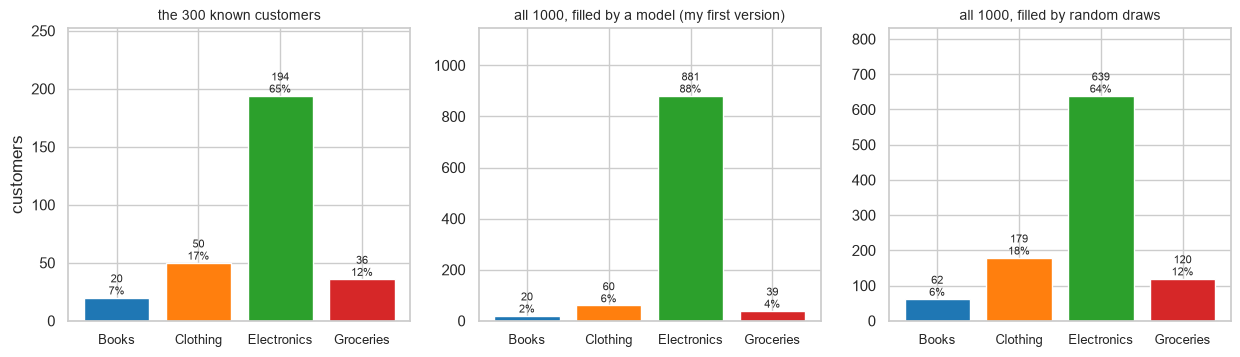

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, (title, values) in zip(axes, [('the 300 known customers', y_known),
                                      ('all 1000, filled by a model (my first version)',
                                       pd.concat([y_known, pd.Series(by_model)])),
                                      ('all 1000, filled by random draws', completed[TARGET])]):
    counts = values.value_counts().reindex(CLASSES).fillna(0)
    bars = ax.bar(CLASSES, counts, color=sns.color_palette('tab10', 4))
    ax.bar_label(bars, [f'{c:.0f}\n{c / counts.sum():.0%}' for c in counts], fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, counts.max() * 1.3)
    ax.tick_params(axis='x', labelsize=9)
axes[0].set_ylabel('customers')
save(fig, 'category_balance.png')
plt.show()

The categories are **clearly unbalanced**. Electronics is 65 % of the known customers, Books only 7 %: almost ten Electronics buyers for every book buyer. Filling with a model makes this much worse (88 % Electronics), because the model guesses "Electronics" nearly every time. Filling with random draws keeps the shares as they are; it doesn't make things better or worse.

Why is this a problem? A model learns mostly from the big class and can reach a good-looking accuracy by ignoring the small ones. With 65 % Electronics, the "model" that always says Electronics is already right 65 % of the time (task 6 looks at this in detail).

**Ways to make it more balanced:**
- **Class weights:** tell the model that a mistake on a book buyer costs about ten times more than a mistake on an Electronics buyer (`class_weight='balanced'` in scikit-learn). No data is changed.
- **Oversampling:** add more examples of the small classes, either copies of existing rows (*random oversampling*) or new, artificial rows between neighboring examples (*SMOTE*).
- **Undersampling:** throw away Electronics rows until all classes are equal. Here this would leave only 4 × 20 = 80 rows, which is too little.
- **More data:** in a real shop, the best fix is to collect more examples of the small classes.

One rule is very important: **balance only the training data, never the test data.** The test must look like the real world, otherwise the score means nothing. In section 4, SMOTE and the oversampling are done inside each training fold. Here is what SMOTE does to the 300 known rows, just to show the idea:

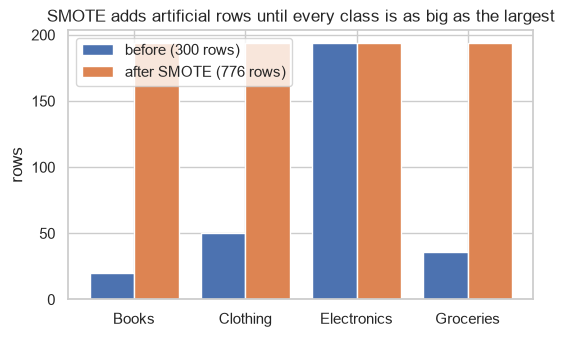

In [15]:
X_bal, y_bal = SMOTE(random_state=SEED).fit_resample(prep.fit_transform(X_known), y_known)
fig, ax = plt.subplots(figsize=(6, 3.5))
before = y_known.value_counts().reindex(CLASSES)
after = pd.Series(y_bal).value_counts().reindex(CLASSES)
x = np.arange(len(CLASSES))
ax.bar(x - 0.2, before, 0.4, label='before (300 rows)')
ax.bar(x + 0.2, after, 0.4, label=f'after SMOTE ({len(y_bal)} rows)')
ax.set_xticks(x, CLASSES)
ax.set_ylabel('rows')
ax.legend()
ax.set_title('SMOTE adds artificial rows until every class is as big as the largest')
save(fig, 'smote_balance.png')
plt.show()

## 4. Confusion matrix and F1 score (task 4)

**Which data?** Only the 300 customers with a real category. The 700 filled values are guesses, and testing a model on guesses would only tell us how well it agrees with the guessing method (the end of this section shows how badly that can mislead).

**How to test with only 300 rows?** With a single 80/20 split, the test set has only 60 customers, and only about 4 of them are book buyers (in the split of my first version, just one). One lucky or unlucky split changes the result a lot. So I use **repeated stratified 5-fold cross-validation**: the 300 rows are cut into 5 parts with the same category shares, each part is the test set once, and the whole thing is repeated 5 times with different cuts. Every number below is an average over 25 tests.

**What to measure?**
- **Accuracy:** the share of correct answers. Easily fooled by a big class.
- **Balanced accuracy:** the share of correct answers *within each category*, averaged over the four categories. Guessing gives 0.25.
- **F1 score** of one category: it combines *precision* (when the model says "Books", how often is it right?) and *recall* (of all book buyers, how many does it find?). It is high only when both are high.
- **Macro F1:** the plain average of the four F1 scores. Every category counts the same.
- **Weighted F1:** the average weighted by the size of each category. Electronics counts 65 %, so this one is also flattered by the big class. My first version reported only this one.

**Baselines.** A model is only useful if it beats simple rules that don't look at the customer at all: always saying "Electronics", and guessing at random with the known shares.

In [16]:
models = {
    'always Electronics': make_pipeline(prep, DummyClassifier(strategy='most_frequent')),
    'random guess with the shares': make_pipeline(prep, DummyClassifier(strategy='stratified', random_state=SEED)),
    'logistic regression': make_pipeline(prep, LogisticRegression(max_iter=2000)),
    'logistic regression, class weights': make_pipeline(prep, LogisticRegression(max_iter=2000, class_weight='balanced')),
    'logistic regression, oversampling': make_imb_pipeline(prep, RandomOverSampler(random_state=SEED), LogisticRegression(max_iter=2000)),
    'decision tree (depth 4)': make_pipeline(prep, DecisionTreeClassifier(max_depth=4, random_state=SEED)),
    'decision tree, class weights': make_pipeline(prep, DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=SEED)),
    'random forest': make_pipeline(prep, RandomForestClassifier(100, random_state=SEED)),
    'random forest, class weights': make_pipeline(prep, RandomForestClassifier(100, class_weight='balanced', min_samples_leaf=5, random_state=SEED)),
    'random forest, SMOTE': make_imb_pipeline(prep, SMOTE(random_state=SEED), RandomForestClassifier(100, random_state=SEED)),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
scoring = {'accuracy': 'accuracy', 'balanced accuracy': 'balanced_accuracy',
           'macro F1': 'f1_macro', 'weighted F1': 'f1_weighted'}
rows = []
for name, model in models.items():
    r = cross_validate(model, X_known, y_known, cv=cv, scoring=scoring)
    rows.append({'model': name, **{k: r[f'test_{k}'].mean() for k in scoring}, 'macro F1 spread': r['test_macro F1'].std()})
comparison = pd.DataFrame(rows).set_index('model')
comparison.to_csv(RESULTS / 'model_comparison.csv', float_format='%.4f')
comparison

,accuracy,balanced accuracy,macro F1,weighted F1,macro F1 spread
model,,,,,
always Electronics,0.647,0.250,0.196,0.508,0.001
random guess with the shares,0.453,0.234,0.235,0.454,0.059
logistic regression,0.640,0.257,0.212,0.511,0.036
"logistic regression, class weights",0.218,0.249,0.189,0.248,0.057
"logistic regression, oversampling",0.241,0.276,0.209,0.272,0.049
decision tree (depth 4),0.583,0.246,0.217,0.498,0.035
"decision tree, class weights",0.192,0.234,0.154,0.197,0.042
random forest,0.635,0.246,0.197,0.506,0.009
"random forest, class weights",0.279,0.241,0.204,0.316,0.053


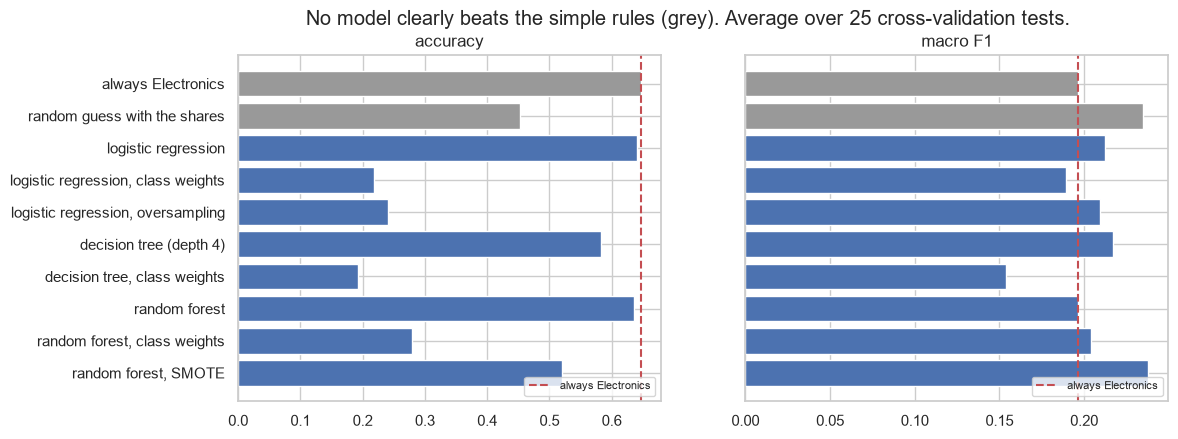

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric in zip(axes, ['accuracy', 'macro F1']):
    colors = ['#999999'] * 2 + ['#4C72B0'] * (len(comparison) - 2)
    ax.barh(comparison.index, comparison[metric], color=colors)
    ax.axvline(comparison.loc['always Electronics', metric], color='#C44E52', ls='--', lw=1.5,
               label='always Electronics')
    ax.set_title(metric)
    ax.legend(loc='lower right', fontsize=8)
axes[0].invert_yaxis()
fig.suptitle('No model clearly beats the simple rules (grey). Average over 25 cross-validation tests.')
save(fig, 'model_comparison.png')
plt.show()

This table is the most important result of the homework:
- **Accuracy:** no model beats "always Electronics" (0.65). The plain random forest and logistic regression come close only because they *also* answer "Electronics" almost every time.
- **Balanced accuracy:** every model is between 0.23 and 0.28, around the 0.25 that guessing gives with four categories.
- **Macro F1:** the best value (about 0.24) is no better than guessing at random with the known shares (also about 0.24), and the spread between the 25 tests (about 0.05) is bigger than the differences between the models.
- **Class weights and oversampling** move the answers away from Electronics, so accuracy drops a lot, but macro F1 doesn't really go up. Balancing helps a model that has *something* to learn; here there is nothing, so it only changes *which* wrong answers we get.

The confusion matrices show this. Each row is the real category, each column is the model's answer, and the numbers are summed over one 5-fold run (every customer is tested exactly once):

always Electronics | F1 per category: {'Books': 0.0, 'Clothing': 0.0, 'Electronics': 0.79, 'Groceries': 0.0}


random forest | F1 per category: {'Books': 0.0, 'Clothing': 0.04, 'Electronics': 0.78, 'Groceries': 0.0}


random forest, SMOTE | F1 per category: {'Books': 0.05, 'Clothing': 0.23, 'Electronics': 0.71, 'Groceries': 0.03}


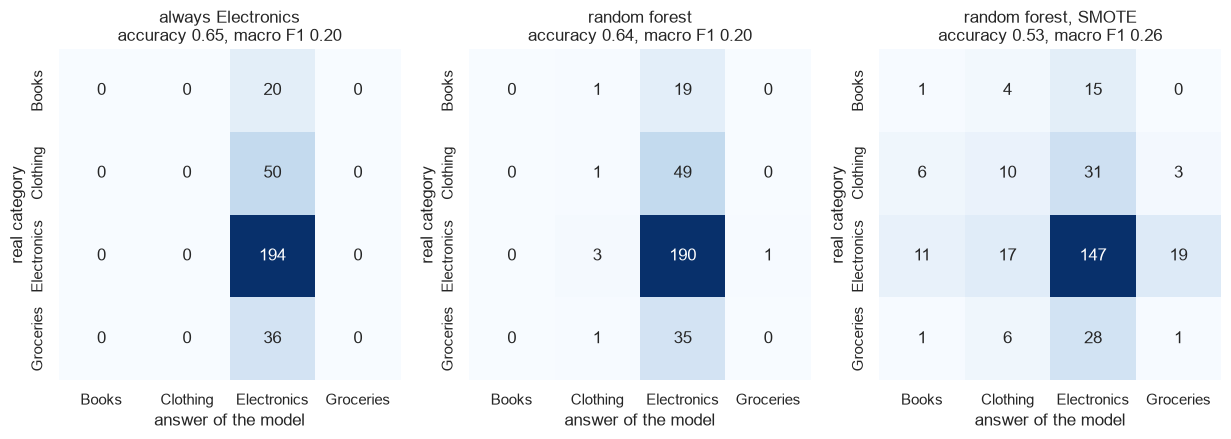

In [18]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
show = ['always Electronics', 'random forest', 'random forest, SMOTE']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, show):
    pred = cross_val_predict(models[name], X_known, y_known, cv=cv5)
    cm = confusion_matrix(y_known, pred, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'{name}\naccuracy {accuracy_score(y_known, pred):.2f}, macro F1 {f1_score(y_known, pred, average="macro"):.2f}')
    ax.set_xlabel('answer of the model')
    ax.set_ylabel('real category')
    print(name, '| F1 per category:', dict(zip(CLASSES, f1_score(y_known, pred, labels=CLASSES, average=None).round(2).tolist())))
save(fig, 'confusion_matrices.png')
plt.show()

- **Always Electronics:** all 300 customers are in the Electronics column. It is right for the 194 Electronics buyers and wrong for everyone else.
- **Random forest:** almost the same picture. It answers "Electronics" for nearly every customer and finds no book buyers. This is the same thing that happened in my first version (60 of 60 test customers were called Electronics).
- **Random forest with SMOTE:** now some answers go to the other columns, but the pattern is about the same in every row: 60 to 80 % of every category still get "Electronics", and the other answers hit the right category about as often as chance would. Only 1 of the 20 book buyers is called "Books". The real category hardly changes what the model answers.

**Is any model better than chance?** A *permutation test* answers this directly: shuffle the categories at random (which destroys any real connection), train and test the model again, and repeat this 200 times. If the model on the real data is not clearly better than on the shuffled data, it has learned nothing.

In [19]:
score, shuffled, p_value = permutation_test_score(
    models['logistic regression, class weights'], X_known, y_known, cv=cv5, scoring='f1_macro',
    n_permutations=200, random_state=SEED)
print(f'macro F1 on the real data:     {score:.3f}')
print(f'macro F1 on shuffled data:     {shuffled.mean():.3f} (spread {shuffled.std():.3f})')
print(f'p-value: {p_value:.3f}')

macro F1 on the real data:     0.214
macro F1 on shuffled data:     0.205 (spread 0.030)
p-value: 0.398


In [20]:
# only Feature_3 and Gender, the two columns with a small p-value in section 1
cols = ['Feature_3', 'Gender']
small_prep = ColumnTransformer([('num', StandardScaler(), ['Feature_3']), ('cat', OneHotEncoder(drop='if_binary'), ['Gender'])])
r = cross_validate(make_pipeline(small_prep, LogisticRegression(max_iter=2000, class_weight='balanced')),
                   df.loc[known, cols], y_known, cv=cv, scoring=scoring)
print({k: round(float(r[f'test_{k}'].mean()), 3) for k in scoring})

{'accuracy': 0.273, 'balanced accuracy': 0.372, 'macro F1': 0.241, 'weighted F1': 0.292}


The permutation test gives a large p-value: the model on the real categories is not better than on shuffled ones.

With only `Feature_3` and `Gender`, the balanced accuracy rises to about 0.37 (guessing: 0.25), so these two columns may carry a small real signal, mostly about book buyers. But the accuracy falls to about 0.27 and the macro F1 stays at 0.24. And because I picked these two columns by looking at the same 300 rows, even this gain is probably too optimistic; a fair check would need new customers.

**Answer to task 4:** with these columns, the purchase category can't be predicted. The best honest "model" is the known shares themselves.

### A warning: testing on filled-in data

What if we fill the 700 empty cells with a model (like my first version) and then train and test a new model on all 1000 rows?

In [21]:
filled_by_model = df[TARGET].copy()
filled_by_model[~known] = by_model
X_tr, X_te, y_tr, y_te = train_test_split(df[NUM + CAT], filled_by_model, test_size=0.2,
                                          stratify=filled_by_model, random_state=SEED)
leak = make_pipeline(prep, RandomForestClassifier(100, random_state=SEED)).fit(X_tr, y_tr)
pred = leak.predict(X_te)
print(f'accuracy {accuracy_score(y_te, pred):.3f}, macro F1 {f1_score(y_te, pred, average="macro"):.3f}')
print('the filling model, tested on its own filled data:', accuracy_score(filled_by_model, forest.predict(df[NUM + CAT])))

accuracy 0.875, macro F1 0.233
the filling model, tested on its own filled data: 0.984


The accuracy jumps from 0.65 to about 0.88, and the filling model even scores 0.98 on its own filled data. Nothing was learned; the test data now contains 700 answers that a model made up, and a model can easily agree with another model. This is called **data leakage**: information from the answer sneaks into the test. The fix is simple: test only on values that were really observed.

## 5. How do the customers behave? Who is valuable? (task 5)

The category can't be predicted, but the table has other information. For a shop, a **valuable customer** is first of all one who spends a lot, so I use `Purchase_Amount` as the measure of value. (In a real shop you would also look at how often and how recently someone buys, but this table has only one purchase per customer.)

median 84.2, mean 100.2, skewness 1.34
top 20 % of customers spend at least 146.5 and bring 42.3% of all money


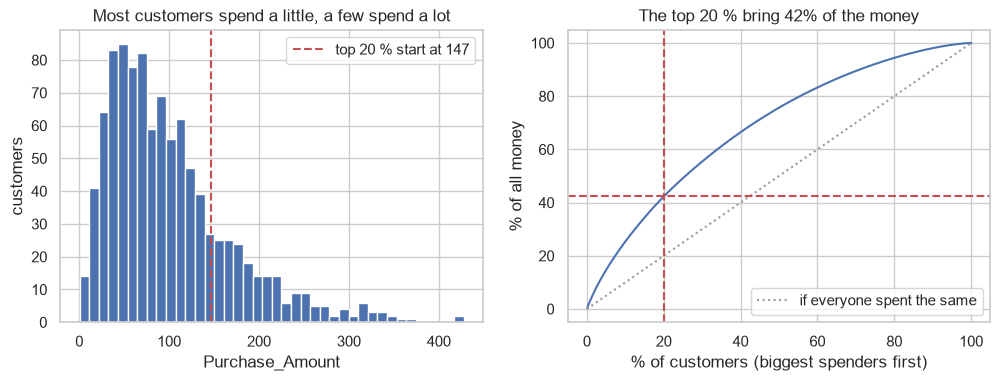

In [22]:
amount = df['Purchase_Amount'].sort_values(ascending=False).reset_index(drop=True)
top_limit = df['Purchase_Amount'].quantile(0.8)
top = df['Purchase_Amount'] >= top_limit
share_top = df.loc[top, 'Purchase_Amount'].sum() / df['Purchase_Amount'].sum()
print(f'median {df["Purchase_Amount"].median():.1f}, mean {df["Purchase_Amount"].mean():.1f}, '
      f'skewness {stats.skew(df["Purchase_Amount"]):.2f}')
print(f'top 20 % of customers spend at least {top_limit:.1f} and bring {share_top:.1%} of all money')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(df['Purchase_Amount'], bins=40, color='#4C72B0')
axes[0].axvline(top_limit, color='#C44E52', ls='--', label=f'top 20 % start at {top_limit:.0f}')
axes[0].set_xlabel('Purchase_Amount')
axes[0].set_ylabel('customers')
axes[0].legend()
axes[0].set_title('Most customers spend a little, a few spend a lot')
x = np.arange(1, len(amount) + 1) / len(amount) * 100
axes[1].plot(x, amount.cumsum() / amount.sum() * 100, color='#4C72B0')
axes[1].plot([0, 100], [0, 100], color='#999999', ls=':', label='if everyone spent the same')
axes[1].axvline(20, color='#C44E52', ls='--')
axes[1].axhline(share_top * 100, color='#C44E52', ls='--')
axes[1].set_xlabel('% of customers (biggest spenders first)')
axes[1].set_ylabel('% of all money')
axes[1].legend(loc='lower right')
axes[1].set_title(f'The top 20 % bring {share_top:.0%} of the money')
save(fig, 'spending.png')
plt.show()

The spending is **skewed to the right**: the median customer spends about 84, but 20 customers spend 300 or more. The top 20 % of customers (everyone who spends at least about 147) bring 42 % of all the money. These are the valuable customers.

**Can we recognize them in advance?** Let's compare them with the other 80 %:

In [23]:
rows = []
for col in ['Age', 'Time_Spent_on_Website', 'Number_of_Items_Viewed', 'Feature_3']:
    p = stats.ttest_ind(df.loc[top, col], df.loc[~top, col], equal_var=False).pvalue
    rows.append([col, df.loc[top, col].mean(), df.loc[~top, col].mean(), p])
for col in CAT:
    p = stats.chi2_contingency(pd.crosstab(df[col], top))[1]
    rows.append([col, '', '', p])
p = stats.chi2_contingency(pd.crosstab(df.loc[known, TARGET], top[known]))[1]
rows.append(['Purchase_Category (300 known)', '', '', p])
pd.DataFrame(rows, columns=['column', 'mean, top 20 %', 'mean, other 80 %', 'p-value']).set_index('column')

,"mean, top 20 %","mean, other 80 %",p-value
column,,,
Age,45.49,43.386,0.071
Time_Spent_on_Website,15.63,15.598,0.963
Number_of_Items_Viewed,10.73,9.739,0.027
Feature_3,4.894,4.747,0.551
Gender,,,0.912
Region,,,0.248
Purchase_Category (300 known),,,0.670


In [24]:
print('share of top customers per group:')
for col in CAT:
    print(' ', col, (pd.crosstab(df[col], top, normalize='index')[True] * 100).round(1).to_dict())
print('  category', (pd.crosstab(df.loc[known, TARGET], top[known], normalize='index')[True] * 100).round(1).to_dict())
r, p = stats.pearsonr(df['Purchase_Amount'], df['Number_of_Items_Viewed'])
print(f'correlation of spending with viewed products: r = {r:.3f}, p = {p:.3f}')

share of top customers per group:
  Gender {'Female': 20.2, 'Male': 19.8}
  Region {'East': 18.8, 'North': 24.2, 'South': 19.7, 'West': 17.5}
  category {'Books': 15.0, 'Clothing': 20.0, 'Electronics': 20.1, 'Groceries': 27.8}
correlation of spending with viewed products: r = 0.078, p = 0.014


The big spenders look almost exactly like everyone else: about the same age (45 against 43, p = 0.07), the same gender split, the same regions, the same time on the website and the same mix of categories. The only small difference is that they look at about one more product (10.7 instead of 9.7, p = 0.03, correlation 0.08). That is far too weak to pick them out in advance.

**Groups by behavior.** Another common way to describe customers is to group them by what they do. I use *k-means* on the three behavior columns (spending, time on the website, viewed products), after scaling them so that each column counts the same:

In [25]:
BEHAVIOR = ['Purchase_Amount', 'Time_Spent_on_Website', 'Number_of_Items_Viewed']
B = StandardScaler().fit_transform(df[BEHAVIOR])
for k in range(2, 7):
    print(f'{k} groups: silhouette {silhouette_score(B, KMeans(k, n_init=10, random_state=SEED).fit_predict(B)):.3f}')

segment = KMeans(4, n_init=10, random_state=SEED).fit_predict(B)
segments = df.groupby(segment)[BEHAVIOR].mean()
segments['customers'] = np.bincount(segment)
segments['share of money'] = df.groupby(segment)['Purchase_Amount'].sum() / df['Purchase_Amount'].sum()
segments = segments.sort_values('Purchase_Amount', ascending=False)
segments.index = [f'segment {i}' for i in range(1, 5)]
segments.round(2)

2 groups: silhouette 0.257
3 groups: silhouette 0.281
4 groups: silhouette 0.303


5 groups: silhouette 0.301


6 groups: silhouette 0.305


,Purchase_Amount,Time_Spent_on_Website,Number_of_Items_Viewed,customers,share of money
segment 1,234.02,16.51,12.20,130,0.30
segment 2,85.24,7.40,6.03,263,0.22
segment 3,80.64,23.65,6.00,279,0.22
segment 4,75.76,14.98,15.52,328,0.25


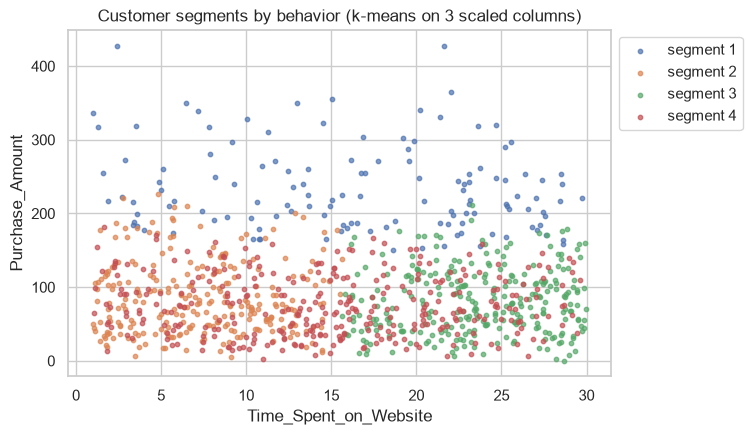

In [26]:
fig, ax = plt.subplots(figsize=(7, 4.5))
order = df.groupby(segment)['Purchase_Amount'].mean().sort_values(ascending=False).index
names = {s: f'segment {i}' for i, s in enumerate(order, start=1)}
for s in order:
    m = segment == s
    ax.scatter(df.loc[m, 'Time_Spent_on_Website'], df.loc[m, 'Purchase_Amount'], s=10, alpha=0.7, label=names[s])
ax.set_xlabel('Time_Spent_on_Website')
ax.set_ylabel('Purchase_Amount')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.set_title('Customer segments by behavior (k-means on 3 scaled columns)')
save(fig, 'segments.png')
plt.show()

Segment 1 is the **big spenders**: 130 customers (13 %), spending on average almost three times as much as the others, and bringing about 30 % of the money. The other three segments spend about the same and differ only in how they use the website: short visits with few viewed products, long visits with few viewed products, and many viewed products.

The silhouette of these groups is only about 0.3, much lower than the 0.59 of the five features. That means the customers don't fall into natural types; k-means is just cutting one big cloud into pieces. The segments are still useful as simple rules for a shop ("send offers to segment 1"), but they are not hidden "kinds" of customers.

**Answer to task 5:**
- The valuable customers are the top 20 % by spending (at least about 147). They bring 42 % of the money.
- In this data they can't be recognized by age, gender, region, time on the website or category. The only weak hint is that they view a few more products.
- So a shop with data like this should find its valuable customers by their **spending history**, not by who they are.
- Because the data is synthetic, these patterns say little about real people. In a real shop I would expect clearer differences.

## 6. How an unbalanced distribution affects accuracy (task 6)

We already saw the main effect in our own data: answering "Electronics" every time gives 65 % accuracy, but it finds **none** of the 106 customers who bought something else. Accuracy counts every customer the same, so the biggest class decides the number.

To see the effect clearly, I need data where a model *can* learn something. So I generate a simple two-class problem with scikit-learn and make the small class rarer and rarer: first 50/50, then 70/30, and so on up to 98/2. For each case I train a logistic regression twice, once normally and once with class weights, and measure it on new data.

In [27]:
rows = []
for majority in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98]:
    X_s, y_s = make_classification(4000, n_features=8, n_informative=4, n_redundant=0, weights=[majority],
                                   class_sep=0.8, flip_y=0.02, random_state=SEED)
    for weights in [None, 'balanced']:
        pred = cross_val_predict(LogisticRegression(max_iter=1000, class_weight=weights), X_s, y_s,
                                 cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
        rows.append({'majority share': majority, 'class weights': weights or 'none',
                     'accuracy': accuracy_score(y_s, pred),
                     'always the majority': max(np.mean(y_s == 0), np.mean(y_s == 1)),
                     'balanced accuracy': balanced_accuracy_score(y_s, pred),
                     'macro F1': f1_score(y_s, pred, average='macro'),
                     'recall of the small class': recall_score(y_s, pred, pos_label=1)})
imbalance = pd.DataFrame(rows)
imbalance.to_csv(RESULTS / 'imbalance_experiment.csv', index=False, float_format='%.4f')
imbalance.round(3)

,majority share,class weights,accuracy,always the majority,balanced accuracy,macro F1,recall of the small class
0,0.50,none,0.699,0.501,0.699,0.698,0.645
1,0.50,balanced,0.698,0.501,0.699,0.698,0.643
2,0.60,none,0.744,0.596,0.706,0.712,0.512
3,0.60,balanced,0.697,0.596,0.686,0.686,0.630
4,0.70,none,0.789,0.695,0.679,0.699,0.395
5,0.70,balanced,0.711,0.695,0.688,0.676,0.629
6,0.80,none,0.845,0.794,0.645,0.678,0.304
7,0.80,balanced,0.729,0.794,0.691,0.652,0.628
8,0.90,none,0.906,0.892,0.569,0.596,0.140
9,0.90,balanced,0.717,0.892,0.672,0.570,0.614


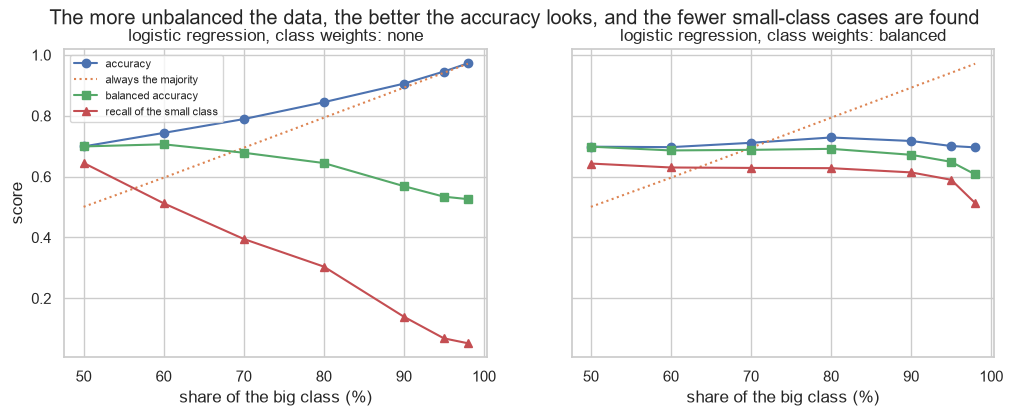

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, weights in zip(axes, ['none', 'balanced']):
    part = imbalance[imbalance['class weights'] == weights]
    for col, style in [('accuracy', '-o'), ('always the majority', ':'), ('balanced accuracy', '-s'),
                       ('recall of the small class', '-^')]:
        ax.plot(part['majority share'] * 100, part[col], style, label=col)
    ax.set_xlabel('share of the big class (%)')
    ax.set_title(f'logistic regression, class weights: {weights}')
axes[0].set_ylabel('score')
axes[0].legend(fontsize=8)
fig.suptitle('The more unbalanced the data, the better the accuracy looks, and the fewer small-class cases are found')
save(fig, 'imbalance_effect.png')
plt.show()

**Without class weights (left):** as the big class grows from 50 % to 98 %, the accuracy *rises* from about 0.70 to 0.97 and looks better and better. At the same time, the share of the small class that the model finds *drops* from about 0.65 to 0.05. At 98/2, the model is barely different from "always say the big class" (the dotted line). Accuracy rewards the model for ignoring the rare cases.

**With class weights (right):** the model keeps finding about 60 % of the small class up to 95/5, and still about half of it at 98/2, and the balanced accuracy stays above 0.6. The price is a lower accuracy, because the model now raises more false alarms on the big class. Which version is better depends on what a mistake costs: missing a fraud case or a sick patient is usually much worse than a false alarm.

**Answer to task 6:**
- With unbalanced classes, **accuracy mostly measures the size of the big class**, not the quality of the model. Always compare it with the "always the majority" baseline.
- Use metrics that give every class the same weight: **balanced accuracy, macro F1, and the recall of each class**. Look at the confusion matrix, not only at one number.
- **Weighted F1** is also pulled up by the big class. In our data it gives 0.51 for "always Electronics", which hides that three of the four categories are never found.
- Balancing (class weights, oversampling, SMOTE) helps when the model has something to learn, as on the right. It can't create information that the columns don't have, as in section 4.
- The same goes for an unbalanced *input* column: values that are rare (for example a region with few customers, or the 20 book buyers) give the model only a few examples, so everything it learns about them is noisy. The gender hint in section 1 (15 of 20 book buyers are women) is exactly such a small-sample result.

## Summary

| Task | Answer |
|---|---|
| 1. Correlation | Only `Feature_1` to `Feature_5` are correlated with each other (strongest *r* = −0.80), because they form four artificial clouds of 250 customers. Nothing is clearly related to the category. I removed no column: none is a copy of another, and the spending columns are needed for task 5. |
| 2. Missing categories | 700 of 1000 are missing, completely at random. A model would call almost all of them Electronics, so I filled them with random draws using the known shares and marked them with `category_filled`. |
| 3. Balance | Unbalanced: 65 % Electronics, 7 % Books. Options: class weights, oversampling or SMOTE (on the training data only), undersampling (too little data here), collecting more data. |
| 4. Confusion matrix and F1 | No model beats "always Electronics" (accuracy 0.65) or random guessing (macro F1 about 0.24). Balanced accuracy is around 0.25 for every model (0.23 to 0.28), and the permutation test confirms that nothing is learned. Testing on model-filled data gives a fake 0.88. |
| 5. Valuable customers | The top 20 % by spending bring 42 % of the money. They look like everyone else in age, gender, region, time on the website and category. |
| 6. Effect of imbalance | Accuracy grows with the size of the big class while the small class is found less and less. Use a baseline, balanced accuracy, macro F1 and per-class recall. |

**What I learned from redoing this homework:** my first version reported 70 % accuracy and looked like a success. It was the share of Electronics in the test set. Comparing with the simplest possible rule before celebrating a number is now the first thing I do.

In [29]:
summary = {
    'rows': len(df),
    'missing categories': int((~known).sum()),
    'known counts': y_known.value_counts().to_dict(),
    'majority share': round(y_known.value_counts(normalize=True).max(), 4),
    'missing at random AUC': round(auc.mean(), 3),
    'r Feature_2 Feature_5': round(corr.loc['Feature_2', 'Feature_5'], 4),
    'r Feature_1 Feature_4': round(corr.loc['Feature_1', 'Feature_4'], 4),
    'groups of Feature_1..5': np.bincount(group)[1:].tolist(),
    'filled by a model': fill['filled by a model (700)'].to_dict(),
    'filled by random draws': fill['filled by random draws (700)'].to_dict(),
    'always Electronics accuracy': round(comparison.loc['always Electronics', 'accuracy'], 4),
    'best macro F1': round(comparison['macro F1'].max(), 4),
    'permutation p-value': round(p_value, 4),
    'top 20 % limit': round(top_limit, 2),
    'top 20 % share of money': round(share_top, 4),
}
with open(RESULTS / 'summary.txt', 'w', encoding='utf-8', newline='\n') as f:
    for k, v in summary.items():
        f.write(f'{k}: {v}\n')
print(open(RESULTS / 'summary.txt', encoding='utf-8').read())

rows: 1000
missing categories: 700
known counts: {'Electronics': 194, 'Clothing': 50, 'Groceries': 36, 'Books': 20}
majority share: 0.6467
missing at random AUC: 0.497
r Feature_2 Feature_5: -0.7976
r Feature_1 Feature_4: 0.6104
groups of Feature_1..5: [250, 250, 250, 250]
filled by a model: {'Books': 0, 'Clothing': 10, 'Electronics': 687, 'Groceries': 3}
filled by random draws: {'Books': 42, 'Clothing': 129, 'Electronics': 445, 'Groceries': 84}
always Electronics accuracy: 0.6467
best macro F1: 0.2377
permutation p-value: 0.398
top 20 % limit: 146.54
top 20 % share of money: 0.4229

